<a href="https://colab.research.google.com/github/yamin975/machine-learning-NIT-srinagar/blob/main/CT_lab_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import torch

#Create a numpy array:
a = np.array([1.0, 2.0, 3.0])

#Create a pytorch tensor
b = torch.tensor([1.0, 2.0, 3.0])

print(a)
print(b)

[1. 2. 3.]
tensor([1., 2., 3.])


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn import datasets

In [ ]:
iris = datasets.load_iris()
X = iris.data
y = iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim #optimizers to minimize loss function


In [ ]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

In [ ]:
class NeuralNetwork(nn.Module):
    def __init__(self):
      super().__init__()

      self.hidden = nn.Linear(4, 16)
      self.relu = nn.ReLU()
      self.output = nn.Linear(16, 3)

    def forward(self, x): #Forward propagation
      x = self.hidden(x)
      x = self.relu(x)
      x = self.output(x)
      return x

model_torch = NeuralNetwork()

#Define loss and Optimizer:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_torch.parameters(), lr=0.01)

In [ ]:
from numpy.random.mtrand import f
epochs = 200

for epoch in range(epochs):
  model_torch.train()
  optimizer.zero_grad()
  outputs = model_torch(X_train_t)
  loss = criterion(outputs, y_train_t.long())
  loss.backward()
  optimizer.step() #Using Adams Optimizer

  if (epoch + 1) % 50 == 0:
    print(
        f"Epoch {epoch + 1}, /{epochs}, "
        f"Loss: {loss.item():.4f}"
    )

#Test the model
model_torch.eval()

with torch.no_grad():
  outputs = model_torch(X_test_t)
  print(outputs)
  y_pred_torch = torch.argmax(   #ArgMax - takes max and it belong to that class
      outputs, dim=1

  ).numpy()
  print(y_pred_torch)

Epoch 50, /200, Loss: 0.2867
Epoch 100, /200, Loss: 0.1106
Epoch 150, /200, Loss: 0.0761
Epoch 200, /200, Loss: 0.0656
tensor([[ -1.9423,   5.0723,   1.3738],
        [ 11.8995,   5.2720, -20.0426],
        [ -9.5239,   4.0289,  14.5903],
        [ -2.2897,   4.8985,   2.0308],
        [ -2.3534,   5.4914,   1.8560],
        [ 10.7270,   5.0630, -18.2525],
        [  0.3864,   5.1006,  -2.4440],
        [ -5.2055,   4.6562,   7.0752],
        [ -3.7777,   4.5540,   4.5725],
        [ -0.4384,   5.1976,  -1.2132],
        [ -4.2679,   4.6413,   5.5419],
        [ 10.3926,   4.6407, -17.5687],
        [ 12.1820,   5.0849, -20.3630],
        [ 10.5081,   4.7184, -17.7730],
        [ 11.7629,   4.8842, -19.6396],
        [ -1.9482,   5.2501,   1.3647],
        [ -6.9516,   3.7618,  10.5057],
        [ -0.7921,   5.0623,  -0.6444],
        [ -2.0732,   4.7249,   1.7445],
        [ -6.9954,   3.6870,  10.5853],
        [  9.9983,   4.6239, -16.9818],
        [ -3.8883,   4.4483,   4.9609],
 

Accuracy:  0.9666666666666667
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.89      0.94         9
           2       0.92      1.00      0.96        11

    accuracy                           0.97        30
   macro avg       0.97      0.96      0.97        30
weighted avg       0.97      0.97      0.97        30



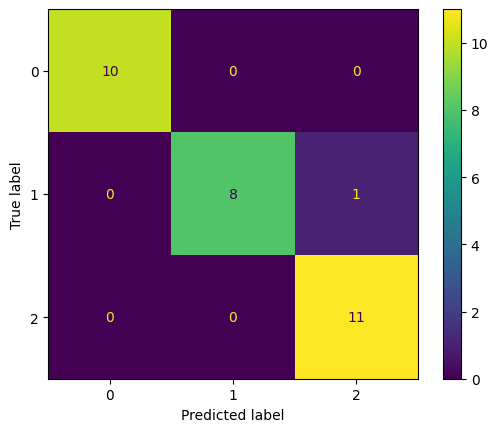

In [ ]:
print("Accuracy: ",
      accuracy_score(y_test, y_pred_torch))

print(classification_report(y_test, y_pred_torch))

cm = confusion_matrix(y_test, y_pred_torch)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()
